# NutriVision · Notebook 01 — CNN EfficientNetB0 con *transfer learning* sobre Food-101
**Proyecto Final de Inteligencia Artificial · Grupo 8 · Tema 8: Clasificación de alimentos para asistentes de nutrición**

Objetivo: entrenar una red neuronal convolucional que clasifique 101 tipos de platos a partir de una foto. El modelo
resultante (`food101_efficientnetb0.keras`) lo usan la app Streamlit y el script de tiempo real con OpenCV.

**Ejecutar en Google Colab con GPU** (Entorno de ejecución → Cambiar tipo → GPU T4). Tiempo aproximado: 1.5–2.5 h.

| Elemento | Decisión |
|---|---|
| Dataset | Food-101: 101 clases, 750 imágenes de entrenamiento y 250 de prueba por clase (75 750 / 25 250) |
| Arquitectura | EfficientNetB0 preentrenada en ImageNet + cabeza de clasificación propia |
| Estrategia | Fase 1: base congelada (extracción de características) · Fase 2: *fine-tuning* de los bloques superiores |
| Regularización | Aumento de datos, *dropout*, *label smoothing*, *early stopping* |


## 1. Configuración del entorno

In [1]:
import json, os, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
# Precisión mixta: cálculos en float16 en la GPU (≈2x más rápido), pesos maestros en float32
keras.mixed_precision.set_global_policy("mixed_float16")

SEMILLA = 42
tf.keras.utils.set_random_seed(SEMILLA)
TAM = 224
LOTE = 64
os.makedirs("models", exist_ok=True); os.makedirs("resultados", exist_ok=True)

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Carga del dataset Food-101
TensorFlow Datasets descarga ~4.6 GB la primera vez. El split `validation` corresponde a las 250 imágenes de prueba
revisadas manualmente por clase; del `train` separamos un 10 % para validar durante el entrenamiento.

In [4]:
!pip install -q importlib_resources

In [5]:
(ds_train, ds_val, ds_test), info = tfds.load(
    "food101", split=["train[:90%]", "train[90%:]", "validation"],
    as_supervised=True, with_info=True, shuffle_files=True)
CLASES = info.features["label"].names
NUM_CLASES = len(CLASES)
print(NUM_CLASES, "clases | train:", len(ds_train), "| val:", len(ds_val), "| test:", len(ds_test))
with open("models/clases.json", "w") as f:
    json.dump(CLASES, f)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.HBRPOI_2.0.0/food101-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.HBRPOI_2.0.0/food101-validation.tfrecord-[0-9][0-9][0-9…

Dataset food101 downloaded and prepared to /root/tensorflow_datasets/food101/2.0.0. Subsequent calls will reuse this data.
101 clases | train: 68175 | val: 7575 | test: 25250


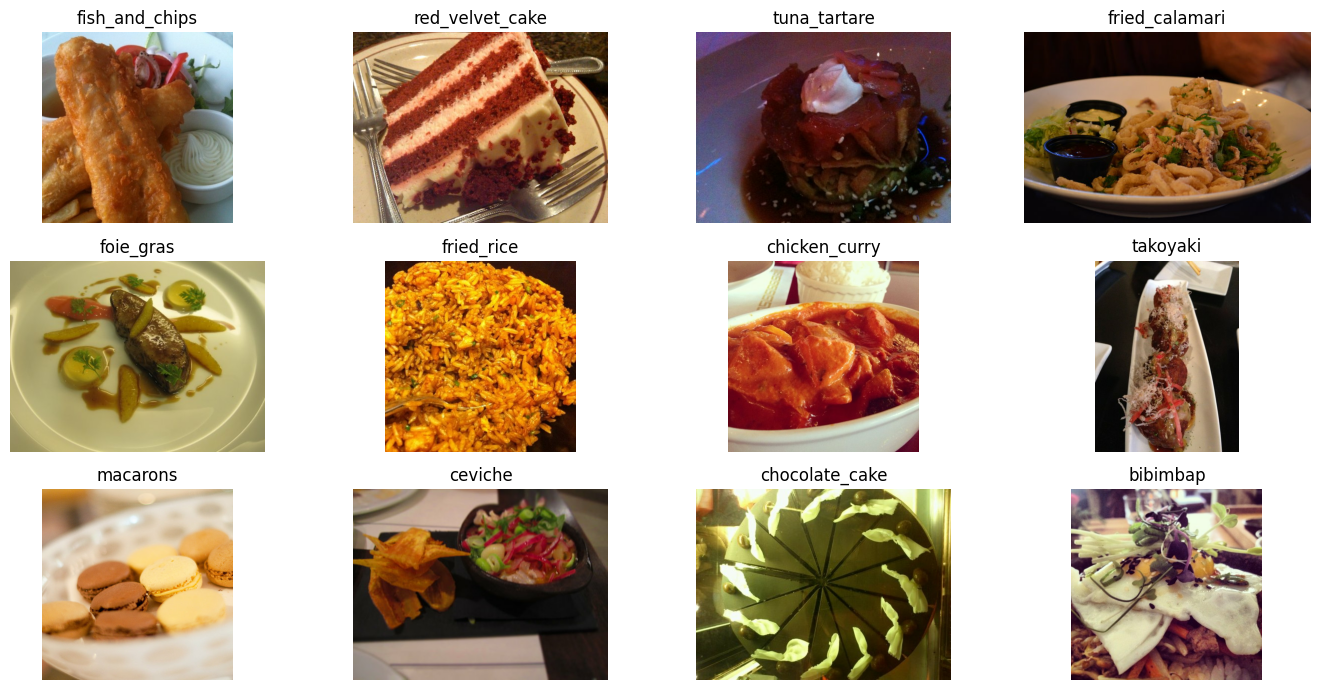

In [6]:
# Vista de ejemplos: imágenes reales, con ruido de etiquetado intencional en el train
plt.figure(figsize=(14, 7))
for i, (img, lab) in enumerate(ds_train.take(12)):
    plt.subplot(3, 4, i + 1); plt.imshow(img); plt.title(CLASES[lab]); plt.axis("off")
plt.tight_layout(); plt.savefig("resultados/ejemplos_dataset.png", dpi=120); plt.show()

## 3. Canal de datos (`tf.data`) y aumento de datos
Las imágenes tienen tamaños distintos (lado mayor 512 px), así que se redimensionan a 224×224. El aumento de datos
(volteo, rotación, zoom, contraste) va **dentro del modelo** como capas de Keras: se activa solo al entrenar.

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

def redimensionar(img, lab):
    return tf.image.resize(img, (TAM, TAM)), lab

def canal(ds, entrenar=False):
    ds = ds.map(redimensionar, num_parallel_calls=AUTOTUNE)
    if entrenar:
        ds = ds.shuffle(2000, seed=SEMILLA)
    return ds.batch(LOTE).prefetch(AUTOTUNE)

tr, va, te = canal(ds_train, True), canal(ds_val), canal(ds_test)

aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="aumento_datos")

## 4. Arquitectura del modelo
**EfficientNetB0** (Tan & Le, 2019) escala de forma balanceada profundidad, ancho y resolución. Está formada por
bloques **MBConv** (convolución *inverted residual* de MobileNetV2 con convolución *depthwise* y atención
*Squeeze-and-Excitation*). Tiene ≈4 M de parámetros en la base, lo que la hace viable en tiempo real en CPU.

```
Entrada 224×224×3 → Aumento de datos → EfficientNetB0 (ImageNet, incluye su normalización)
→ GlobalAveragePooling2D (1280) → BatchNormalization → Dropout(0.3) → Dense(101, softmax)
```

In [8]:
base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(TAM, TAM, 3))
base.trainable = False

entradas = keras.Input((TAM, TAM, 3), name="imagen")
x = aumento(entradas)
x = base(x, training=False)            # BatchNorm de la base en modo inferencia también al afinar
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
salidas = layers.Dense(NUM_CLASES, activation="softmax", dtype="float32", name="clasificador")(x)
modelo = keras.Model(entradas, salidas, name="nutrivision_efficientnetb0")
modelo.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "nutrivision_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_datos (Sequential)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clasificador (Dense)            │ (None, 101)            │       129,381 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,184,072 (15.96 MB)

 Trainable params: 131,941 (515.39 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

## 5. Fase 1 — extracción de características (base congelada)
Solo se entrena la cabeza (≈130 mil parámetros). *Label smoothing* (0.1) reduce la sobreconfianza ante etiquetas ruidosas.

In [9]:
perdida = keras.losses.CategoricalCrossentropy(label_smoothing=0.1)
def a_onehot(x, y): return x, tf.one_hot(y, NUM_CLASES)
tr1, va1, te1 = tr.map(a_onehot), va.map(a_onehot), te.map(a_onehot)

metricas = ["accuracy", keras.metrics.TopKCategoricalAccuracy(k=5, name="top5")]
modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss=perdida, metrics=metricas)
t0 = time.time()
hist1 = modelo.fit(tr1, validation_data=va1, epochs=3)
print(f"Fase 1: {(time.time() - t0) / 60:.1f} min")

Epoch 1/3
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 211s 174ms/step - accuracy: 0.4379 - loss: 2.8708 - top5: 0.6962 - val_accuracy: 0.6137 - val_loss: 2.1841 - val_top5: 0.8454
Epoch 2/3
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 183s 168ms/step - accuracy: 0.5462 - loss: 2.3985 - top5: 0.7994 - val_accuracy: 0.6403 - val_loss: 2.0880 - val_top5: 0.8611
Epoch 3/3
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 189s 174ms/step - accuracy: 0.5701 - loss: 2.3060 - top5: 0.8178 - val_accuracy: 0.6445 - val_loss: 2.0636 - val_top5: 0.8673
Fase 1: 9.7 min


## 6. Fase 2 — *fine-tuning*
Se descongelan los bloques superiores (desde `block4a`) con una tasa de aprendizaje 10 veces menor para ajustar las
características de alto nivel (texturas y formas de comida) sin destruir lo aprendido en ImageNet. Las capas
BatchNormalization se mantienen congeladas.

In [10]:
base.trainable = True
congelar = True
for capa in base.layers:
    if capa.name.startswith("block4a"):
        congelar = False
    capa.trainable = (not congelar) and not isinstance(capa, layers.BatchNormalization)
print("Parámetros entrenables:", sum(np.prod(v.shape) for v in modelo.trainable_variables))

EPOCAS_FT = 10
pasos = len(tr1) * EPOCAS_FT
lr = keras.optimizers.schedules.CosineDecay(1e-4, decay_steps=pasos, alpha=0.05)
modelo.compile(optimizer=keras.optimizers.Adam(lr), loss=perdida, metrics=metricas)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("models/food101_efficientnetb0.keras", monitor="val_accuracy",
                                    save_best_only=True),
]
t0 = time.time()
hist2 = modelo.fit(tr1, validation_data=va1, epochs=EPOCAS_FT, callbacks=callbacks)
print(f"Fase 2: {(time.time() - t0) / 60:.1f} min")

Parámetros entrenables: 4034655
Epoch 1/10
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 305s 246ms/step - accuracy: 0.6599 - loss: 2.0014 - top5: 0.8760 - val_accuracy: 0.7081 - val_loss: 1.8588 - val_top5: 0.9013
Epoch 2/10
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 261s 241ms/step - accuracy: 0.7191 - loss: 1.8086 - top5: 0.9096 - val_accuracy: 0.7298 - val_loss: 1.7627 - val_top5: 0.9135
Epoch 3/10
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 263s 244ms/step - accuracy: 0.7515 - loss: 1.7000 - top5: 0.9279 - val_accuracy: 0.7498 - val_loss: 1.7125 - val_top5: 0.9197
Epoch 4/10
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 258s 238ms/step - accuracy: 0.7798 - loss: 1.6145 - top5: 0.9390 - val_accuracy: 0.7613 - val_loss: 1.6728 - val_top5: 0.9224
Epoch 5/10
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 264s 244ms/step - accuracy: 0.8020 - loss: 1.5406 - top5: 0.9511 - val_accuracy: 0.7625 - val_loss: 1.6593 - val_top5: 0.9277
Epoch 6/10
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 259s 239ms/step - accuracy: 0.8198 - loss: 1.4914 - top5: 0.9574 - val_accuracy: 0.767

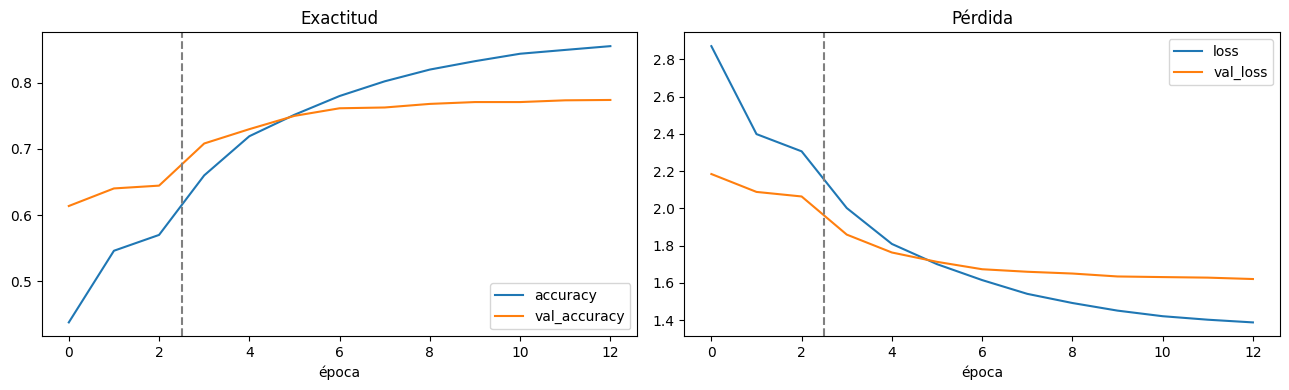

In [11]:
# Curvas de aprendizaje de ambas fases
h = {k: hist1.history[k] + hist2.history[k] for k in hist1.history}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k in ("accuracy", "val_accuracy"): ax[0].plot(h[k], label=k)
for k in ("loss", "val_loss"): ax[1].plot(h[k], label=k)
for a, t in zip(ax, ("Exactitud", "Pérdida")):
    a.axvline(len(hist1.history["loss"]) - 0.5, ls="--", c="gray"); a.set_title(t); a.set_xlabel("época"); a.legend()
plt.tight_layout(); plt.savefig("resultados/curvas_cnn.png", dpi=120); plt.show()

## 7. Evaluación en el conjunto de prueba (25 250 imágenes)

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

y_true = np.concatenate([y.numpy() for _, y in te])
t0 = time.time()
prob = modelo.predict(te, verbose=1)
ms_por_img = (time.time() - t0) / len(y_true) * 1000
y_pred = prob.argmax(1)
top5 = np.mean([y in np.argsort(p)[-5:] for y, p in zip(y_true, prob)])
resultados = {
    "modelo": "EfficientNetB0 transfer learning",
    "accuracy_top1": float((y_pred == y_true).mean()),
    "accuracy_top5": float(top5),
    "f1_macro": float(f1_score(y_true, y_pred, average="macro")),
    "parametros": int(modelo.count_params()),
    "ms_por_imagen_gpu": ms_por_img,
    "epocas": len(h["loss"]),
}
print(json.dumps(resultados, indent=2))
json.dump(resultados, open("resultados/metricas_cnn.json", "w"), indent=2)
reporte = classification_report(y_true, y_pred, target_names=CLASES, output_dict=True)

395/395 ━━━━━━━━━━━━━━━━━━━━ 61s 144ms/step
{
  "modelo": "EfficientNetB0 transfer learning",
  "accuracy_top1": 0.009584158415841584,
  "accuracy_top5": 0.04883168316831683,
  "f1_macro": 0.009572471024673727,
  "parametros": 4184072,
  "ms_por_imagen_gpu": 3.246882646390707,
  "epocas": 13
}


In [13]:
# Clases con mejor y peor F1, y pares que más se confunden
f1 = sorted(((c, reporte[c]["f1-score"]) for c in CLASES), key=lambda t: t[1])
print("Peores 10:", [(c, round(v, 2)) for c, v in f1[:10]])
print("Mejores 10:", [(c, round(v, 2)) for c, v in f1[-10:]])
cm = confusion_matrix(y_true, y_pred)
np.fill_diagonal(cm, 0)
pares = sorted(((cm[i, j], CLASES[i], CLASES[j]) for i in range(NUM_CLASES) for j in range(NUM_CLASES)), reverse=True)[:10]
for n, a, b in pares: print(f"{a:25s} → {b:25s} {n}")
json.dump({"peores": f1[:10], "mejores": f1[-10:], "confusiones": [(int(n), a, b) for n, a, b in pares]},
          open("resultados/analisis_errores_cnn.json", "w"), indent=2)

Peores 10: [('carrot_cake', 0.0), ('clam_chowder', 0.0), ('eggs_benedict', 0.0), ('filet_mignon', 0.0), ('lobster_bisque', 0.0), ('macaroni_and_cheese', 0.0), ('samosa', 0.0), ('shrimp_and_grits', 0.0), ('spaghetti_bolognese', 0.0), ('tiramisu', 0.0)]
Mejores 10: [('deviled_eggs', 0.02), ('bruschetta', 0.02), ('donuts', 0.02), ('french_onion_soup', 0.02), ('nachos', 0.02), ('huevos_rancheros', 0.02), ('pulled_pork_sandwich', 0.02), ('gnocchi', 0.02), ('greek_salad', 0.03), ('bibimbap', 0.03)]
lobster_bisque            → samosa                    11
ramen                     → greek_salad               10
macaroni_and_cheese       → grilled_cheese_sandwich   10
steak                     → lobster_roll_sandwich     9
risotto                   → pad_thai                  9
prime_rib                 → club_sandwich             9
hummus                    → lobster_bisque            9
gyoza                     → beef_carpaccio            9
greek_salad               → hot_dog                

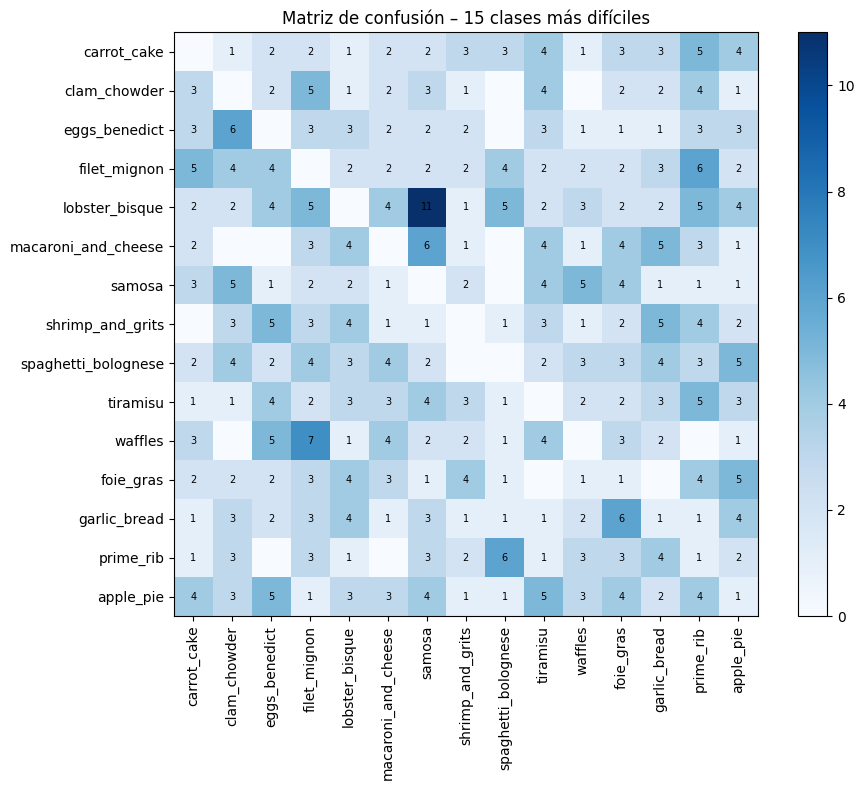

In [14]:
# Matriz de confusión de las 15 clases con peor F1
idx = [CLASES.index(c) for c, _ in f1[:15]]
cm_full = confusion_matrix(y_true, y_pred)
sub = cm_full[np.ix_(idx, idx)]
plt.figure(figsize=(10, 8)); plt.imshow(sub, cmap="Blues")
plt.xticks(range(15), [CLASES[i] for i in idx], rotation=90); plt.yticks(range(15), [CLASES[i] for i in idx])
for i in range(15):
    for j in range(15):
        if sub[i, j]: plt.text(j, i, sub[i, j], ha="center", va="center", fontsize=7)
plt.title("Matriz de confusión – 15 clases más difíciles"); plt.colorbar(); plt.tight_layout()
plt.savefig("resultados/confusion_cnn.png", dpi=120); plt.show()

## 8. Prueba del flujo completo con OpenCV (detección del plato + clasificación)
Se sube una foto propia y se aplica el mismo preprocesamiento que usa la app: CLAHE → detección del plato
(Hough / contornos) → recorte → clasificación.

In [16]:
# Sube el zip del proyecto (proyecto_nutricion_ia.zip) para reutilizar el módulo src/vision.py
import cv2, sys, zipfile
from google.colab import files
zip_proyecto = list(files.upload().keys())[0]
zipfile.ZipFile(zip_proyecto).extractall("/content")
sys.path.insert(0, "/content/proyecto_nutricion_ia")
from src.vision import mejorar_iluminacion, detectar_plato, recortar, preparar_para_modelo, dibujar_resultado

nombre = list(files.upload().keys())[0]
img = cv2.imread(nombre)
mej = mejorar_iluminacion(img)
caja = detectar_plato(mej)
p = modelo.predict(preparar_para_modelo(recortar(mej, caja))[None].astype("float32"), verbose=0)[0]
top = np.argsort(p)[::-1][:3]
print([(CLASES[i], f"{p[i]:.1%}") for i in top])
plt.imshow(cv2.cvtColor(dibujar_resultado(img, caja, CLASES[top[0]], p[top[0]]), cv2.COLOR_BGR2RGB)); plt.axis("off")

Saving proyecto_nutricion_ia.zip to proyecto_nutricion_ia (1).zip


KeyboardInterrupt: 

In [17]:
import cv2, sys, os, zipfile
from google.colab import files
if not os.path.exists("/content/proyecto_nutricion_ia/src/vision.py"):
    print("Selecciona el archivo proyecto_nutricion_ia.zip")
    zip_proyecto = list(files.upload().keys())[0]
    zipfile.ZipFile(zip_proyecto).extractall("/content")
sys.path.insert(0, "/content/proyecto_nutricion_ia")
from src.vision import mejorar_iluminacion, detectar_plato, recortar, preparar_para_modelo, dibujar_resultado
print("Módulo de visión cargado")

Módulo de visión cargado


## 9. Exportar
Descarga `models/food101_efficientnetb0.keras`, `models/clases.json` y la carpeta `resultados/` y cópialos en las
carpetas del mismo nombre del proyecto. La app detecta el modelo automáticamente.

In [18]:
!zip -qr entregable_cnn.zip models resultados
files.download("entregable_cnn.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>